# 01 – Energy analysis (Branch 2: From grey to green) – Part 1

**Question (Branch 2):** Has energy risk declined? This notebook looks at the size of energy cost (its share of margin and cost), physical consumption, the implied energy price, a price-volume decomposition and energy intensity. The mix effect is covered in the next notebook.

**Hypothesis H2:**
> **H2 (Branch 2):** Part of the decline in the energy share after 2022 comes from lower energy prices (expected to bring the share back to the pre-crisis level of 33–36%), and the part below that level comes from the green transformation (alternative fuels, solar, waste heat) and portfolio changes. Test: price-volume decomposition, energy consumption per ton, mix effect.

**Data:** Only `output/tables/annual_master.csv` (no PDFs are read). Default view `view = own` (each year's own report).

**Keep in mind while reading:**
- Amounts for 2016–2022 are **nominal**, amounts for 2023–2025 are **IAS 29** (inflation-adjusted). The two series are not merged; charts show a line between 2022 and 2023.
- Dollar conversion: annual average rate in nominal years, year-end rate in IAS 29 years (EVDS).
- Findings carry no causal claims: the wording is "together with X".

## 1. Loading the data

We read the master table and keep the `own` rows (2016–2025) for the analysis. We define folder paths to save the charts under `output/figures/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The notebook can be run from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "output" / "tables"
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Colours (fixed order; the same indicator has the same colour in every chart)
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
C_GREY, C_INK, C_MUTED = "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})

In [2]:
master = pd.read_csv(TABLES / "annual_master.csv")
own = master[(master["view"] == "own") & master["year"].between(2016, 2025)].set_index("year").sort_index()
print(f"Total rows: {len(master)}, own rows (2016–2025): {len(own)}")
own[["basis", "report_year"]].T

Total rows: 20, own rows (2016–2025): 10


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
basis,nominal,nominal,nominal,nominal,nominal,nominal,nominal,tms29,tms29,tms29
report_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025


**2022 bridge year:** 2022 has two versions. The one in its own report is **nominal** and excludes SBS (international white cement); the one in the 2023 report is rolled forward to end-2023 purchasing power under **IAS 29** and includes SBS. The table below shows them side by side. The default 2022 value in the analysis is the own report; the IAS 29 version is shown separately in the charts with a hollow marker.

In [3]:
BRIDGE_COLS = ["basis", "revenue", "energy_cost", "total_production_cost", "gross_margin",
               "energy_share_production_cost", "energy_to_revenue", "usd_try_rate_used",
               "energy_cost_usd", "total_energy_consumption", "implied_energy_price_usd_per_mwh",
               "clinker_production"]
bridge_2022 = master[(master["year"] == 2022) & master["view"].isin(["own", "restated_in_2023"])]
bridge_2022 = bridge_2022.set_index("view")[BRIDGE_COLS]
r2022 = bridge_2022.loc["restated_in_2023"]  # used as a hollow marker in later sections
bridge_2022.T

view,own,restated_in_2023
basis,nominal,tms29
revenue,8582005230.0,20820386000.0
energy_cost,3632105128.0,7871428000.0
total_production_cost,6097149264.0,14967621000.0
gross_margin,0.172381,0.114342
energy_share_production_cost,0.595705,0.525897
energy_to_revenue,0.423223,0.378063
usd_try_rate_used,16.56377,29.3973
energy_cost_usd,219280099.15617,267760236.484303
total_energy_consumption,6439517.0,6610806.0


## 2. Energy weight and gross margin (2016–2025)

We track three ratios in the same chart:
- **energy_to_revenue**: energy cost / revenue
- **energy_share_production_cost**: energy cost / total production cost
- **gross_margin**: gross margin

All three are ratios, so a single axis (%) is enough. The vertical line between 2022 and 2023 marks the accounting change (IAS 29); the small triangles at the bottom mark scope breaks. The IAS 29 + SBS version of 2022 is shown with a hollow marker.

In [4]:
RATIO_COLS = {"energy_to_revenue": ("Energy / revenue", C_BLUE),
              "energy_share_production_cost": ("Energy / production cost", C_ORANGE),
              "gross_margin": ("Gross margin", C_AQUA)}
ratios = (own[list(RATIO_COLS)] * 100).round(1)
ratios.loc["2022 (IAS 29 + SBS)"] = (r2022[list(RATIO_COLS)].astype(float) * 100).round(1)
ratios

,energy_to_revenue,energy_share_production_cost,gross_margin
year,,,
2016,22.9,33.2,32.1
2017,23.3,33.1,26.5
2018,27.4,36.4,23.9
2019,28.2,36.4,17.6
2020,34.6,46.7,22.5
2021,37.3,50.7,19.0
2022,42.3,59.6,17.2
2023,24.5,40.6,19.7
2024,22.3,29.9,21.5


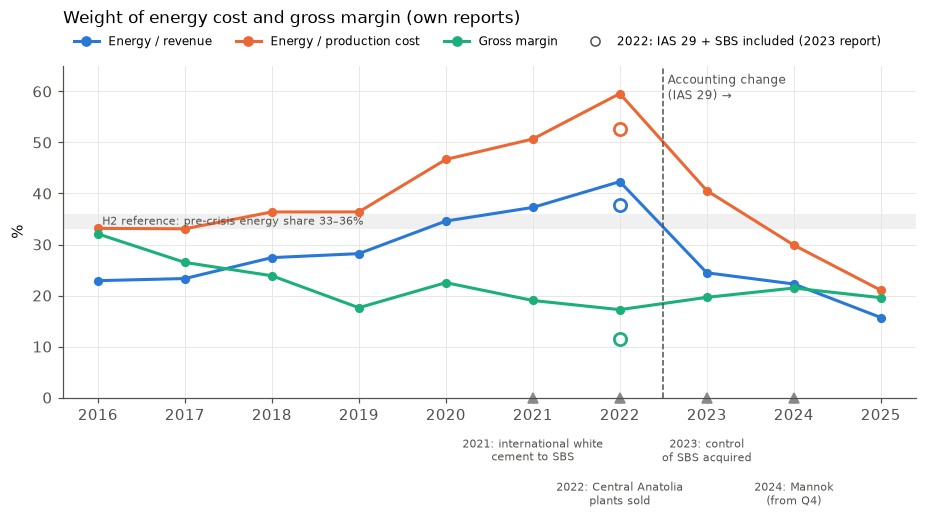

In [5]:
# Scope breaks – x position: year it took effect
SCOPE_BREAKS = [(2021, "2021: international white\ncement to SBS"),
                (2022, "2022: Central Anatolia\nplants sold"),
                (2023, "2023: control\nof SBS acquired"),
                (2024, "2024: Mannok\n(from Q4)")]

def mark_series_break(ax, label=True):
    ax.axvline(2022.5, color=C_MUTED, linestyle="--", linewidth=1)
    if label:
        ax.text(2022.55, 0.98, "Accounting change\n(IAS 29) →", transform=ax.get_xaxis_transform(),
                va="top", ha="left", fontsize=8, color=C_MUTED)

def mark_scope_breaks(ax, years=None):
    for k, (y, txt) in enumerate(SCOPE_BREAKS):
        if years is not None and y not in years:
            continue
        ax.plot(y, 0.0, marker="^", markersize=7, color=C_GREY, transform=ax.get_xaxis_transform(), clip_on=False)
        # labels are spread over two rows so they do not overlap
        ax.text(y, -0.12 - 0.13 * (k % 2), txt, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=C_MUTED)

fig, ax = plt.subplots(figsize=(10, 5.2))
for col, (lab, c) in RATIO_COLS.items():
    ax.plot(own.index, own[col] * 100, marker="o", markersize=5, color=c, label=lab)
    ax.plot(2022, r2022[col] * 100, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=c, markeredgewidth=1.8, linestyle="none")
ax.axhspan(33, 36, color=C_GREY, alpha=0.12, linewidth=0)
ax.text(2016.05, 34.5, "H2 reference: pre-crisis energy share 33–36%", fontsize=7.5, color=C_MUTED, va="center")
mark_series_break(ax)
mark_scope_breaks(ax)
ax.set_xticks(range(2016, 2026))
ax.set_xlim(2015.6, 2025.4)
ax.set_ylim(0, 65)
ax.set_ylabel("%")
ax.set_title("Weight of energy cost and gross margin (own reports)", loc="left", fontsize=11)
handles = [Line2D([], [], color=c, marker="o", label=l) for l, c in RATIO_COLS.values()]
handles.append(Line2D([], [], color=C_MUTED, marker="o", markerfacecolor="white", linestyle="none", label="2022: IAS 29 + SBS included (2023 report)"))
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.02), fontsize=8, ncol=4)
ax.set_title("Weight of energy cost and gross margin (own reports)", loc="left", fontsize=11, pad=28)
fig.subplots_adjust(bottom=0.3)
fig.savefig(FIGS / "01_energy_weight_and_margin.png", bbox_inches="tight")
plt.show()

**What we see:** The share of energy in production cost is in the 33–36% band in 2016–2019, rises to 60% in 2022, then falls to 41% in 2023, 30% in 2024 and 21% in 2025; i.e. from 2024 it is below H2's reference band. Gross margin stays in the 17–21% range over the same period; the fall in the energy share is not accompanied by a rise of similar size in the margin.

*Note:* The version of 2019 in the 2020 report (excluding international white cement) shows an energy share of 47%. So the 33–36% band is the value for the scope **including** international white cement; it is not directly comparable with the narrower scope of 2020–2022. After 2023 SBS is consolidated again, so the scope is closer to 2016–2019.

## 3. Physical consumption and implied energy price (2020–2025)

Implied price = energy cost / total energy consumption (MWh). This is an "average price paid" indicator; it combines the fuel and electricity mix, the low cost of alternative fuels and the FX effect. MWh data cannot be used before 2020 because of a definition difference.

The table shows which report each year's physical data comes from and the known scope notes.

In [6]:
# Which report did total energy consumption come from? (esg_source column)
def mwh_source(row):
    src = str(row["esg_source"])
    if "total_energy_consumption(" in src:
        rep = src.split("total_energy_consumption(")[1].split(")")[0]
        return f"restated: {rep}"
    return "own report"

# Scope notes: summary from output/checks/esg_report_boundaries.csv
SCOPE_NOTE = {
    2020: "MWh not in own report; from the 2021 report",
    2021: "Physical data Turkey only",
    2022: "Physical data Turkey + Cyprus terminal",
    2023: "SBS (Buñol, USA) included",
    2024: "Mannok EXCLUDED from physical data, Q4 included in financials",
    2025: "Mannok scope unclear line by line (some footnotes say 'excluded')",
}
phys = own.loc[2020:2025, ["basis", "energy_cost", "energy_cost_usd", "total_energy_consumption",
                           "implied_energy_price_try_per_mwh", "implied_energy_price_usd_per_mwh"]].copy()
phys["mwh_source"] = own.loc[2020:2025].apply(mwh_source, axis=1)
phys["scope_note"] = pd.Series(SCOPE_NOTE)
phys_view = phys.assign(
    energy_cost_mn_try=(phys["energy_cost"] / 1e6).round(0),
    energy_cost_mn_usd=(phys["energy_cost_usd"] / 1e6).round(1),
    energy_mn_mwh=(phys["total_energy_consumption"] / 1e6).round(2),
    price_try_per_mwh=phys["implied_energy_price_try_per_mwh"].round(0),
    price_usd_per_mwh=phys["implied_energy_price_usd_per_mwh"].round(1),
)[["basis", "energy_cost_mn_try", "energy_cost_mn_usd", "energy_mn_mwh", "price_try_per_mwh",
   "price_usd_per_mwh", "mwh_source", "scope_note"]]
phys_view

,basis,energy_cost_mn_try,energy_cost_mn_usd,energy_mn_mwh,price_try_per_mwh,price_usd_per_mwh,mwh_source,scope_note
year,,,,,,,,
2020,nominal,718.0,102.5,7.14,101.0,14.4,restated: 2021 report,MWh not in own report; from the 2021 report
2021,nominal,1396.0,157.1,7.67,182.0,20.5,own report,Physical data Turkey only
2022,nominal,3632.0,219.3,6.44,564.0,34.1,own report,Physical data Turkey + Cyprus terminal
2023,tms29,5015.0,170.6,6.35,789.0,26.9,own report,"SBS (Buñol, USA) included"
2024,tms29,6269.0,178.0,6.36,986.0,28.0,own report,"Mannok EXCLUDED from physical data, Q4 include..."
2025,tms29,7208.0,168.2,7.19,1003.0,23.4,own report,Mannok scope unclear line by line (some footno...


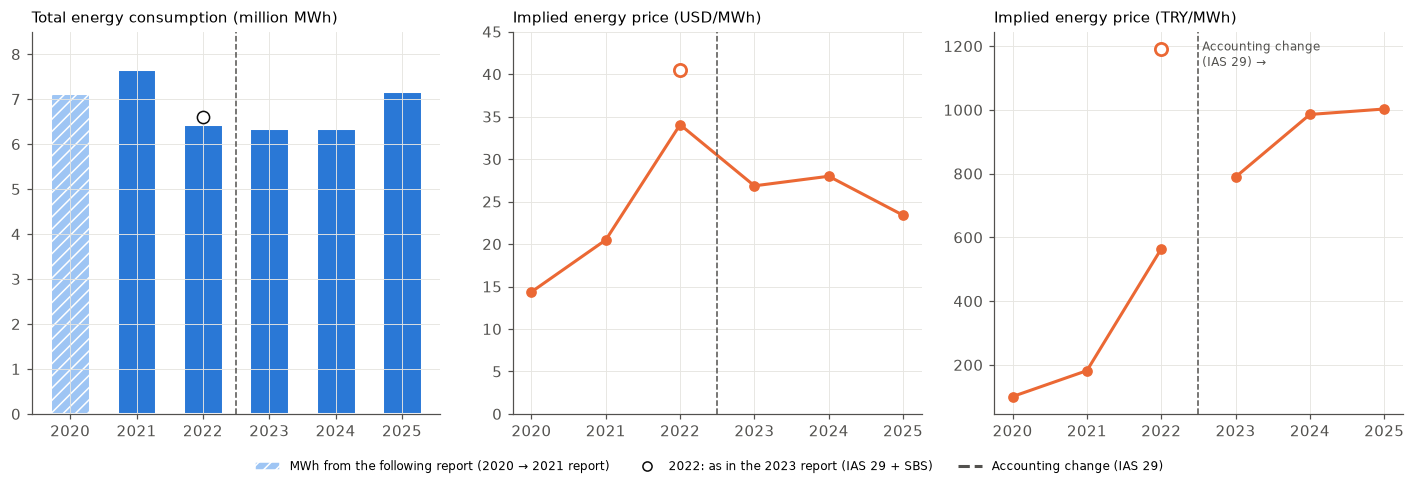

In [7]:
yrs = phys.index.values
restated_src = phys["mwh_source"] != "own report"
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

# (a) physical consumption
ax = axes[0]
bars = ax.bar(yrs, phys["total_energy_consumption"] / 1e6, width=0.6, color=C_BLUE, edgecolor="white", linewidth=2)
for b, rs in zip(bars, restated_src):
    if rs:
        b.set_hatch("///"); b.set_facecolor("#9ec5f4")
ax.plot(2022, r2022["total_energy_consumption"] / 1e6, marker="o", markersize=8, markerfacecolor="white",
        markeredgecolor=C_INK, linestyle="none")
ax.set_title("Total energy consumption (million MWh)", loc="left", fontsize=10)
ax.set_ylim(0, 8.5)

# (b) implied price USD/MWh
ax = axes[1]
ax.plot(yrs, phys["implied_energy_price_usd_per_mwh"], marker="o", color=C_ORANGE)
ax.plot(2022, r2022["implied_energy_price_usd_per_mwh"], marker="o", markersize=8, markerfacecolor="white",
        markeredgecolor=C_ORANGE, markeredgewidth=1.8, linestyle="none")
ax.set_title("Implied energy price (USD/MWh)", loc="left", fontsize=10)
ax.set_ylim(0, 45)

# (c) implied price TRY/MWh – nominal and IAS 29 as separate lines
ax = axes[2]
nom = phys[phys["basis"] == "nominal"]; tms = phys[phys["basis"] == "tms29"]
ax.plot(nom.index, nom["implied_energy_price_try_per_mwh"], marker="o", color=C_ORANGE)
ax.plot(tms.index, tms["implied_energy_price_try_per_mwh"], marker="o", color=C_ORANGE)
ax.plot(2022, r2022["energy_cost"] / r2022["total_energy_consumption"], marker="o", markersize=8,
        markerfacecolor="white", markeredgecolor=C_ORANGE, markeredgewidth=1.8, linestyle="none")
ax.set_title("Implied energy price (TRY/MWh)", loc="left", fontsize=10)

for ax in axes:
    ax.set_xticks(yrs)
    mark_series_break(ax, label=(ax is axes[2]))
legend_items = [Patch(facecolor="#9ec5f4", hatch="///", edgecolor="white", label="MWh from the following report (2020 → 2021 report)"),
                Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor=C_INK, linestyle="none",
                       label="2022: as in the 2023 report (IAS 29 + SBS)"),
                Line2D([], [], color=C_MUTED, linestyle="--", label="Accounting change (IAS 29)")]
fig.legend(handles=legend_items, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(FIGS / "01_energy_consumption_and_implied_price.png", bbox_inches="tight")
plt.show()

**What we see:** Physical consumption is in the 6.4–7.7 million MWh range throughout 2020–2025, with no clear trend. The implied price, on the other hand, rises from 14 USD/MWh in 2020 to 34 USD/MWh in 2022 (40.5 in the IAS 29 version of the 2023 report), then falls to 27 in 2023 and 23 USD/MWh in 2025; the 2025 level is still about 1.6 times that of 2020.

*Note:* The TRY/MWh chart is not comparable between 2022 and 2023 (nominal → IAS 29). In 2024 the financial cost includes Mannok's Q4 while physical consumption excludes Mannok; this may push the 2024 implied price up somewhat.

## 4. Price-volume decomposition (USD, 2020 → 2025)

For each pair of years we split the change in energy cost into two parts:
- **Volume effect** = (current-year MWh − prior-year MWh) × prior-year price
- **Price effect** = (current-year price − prior-year price) × current-year MWh

The two effects add up exactly to the change in energy cost (no residual term). The calculation is in USD and uses the `own` rows. **The 2022 → 2023 transition spans the switch from the nominal series to the IAS 29 series**; this row is flagged and should be interpreted with care.

In [8]:
def price_volume(E0, Q0, E1, Q1):
    P0, P1 = E0 / Q0, E1 / Q1
    vol = (Q1 - Q0) * P0
    price = (P1 - P0) * Q1
    return P0, P1, vol, price

d = own.loc[2020:2025, ["basis", "energy_cost_usd", "total_energy_consumption"]]
rows = []
for y in range(2021, 2026):
    a, b = d.loc[y - 1], d.loc[y]
    P0, P1, vol, price = price_volume(a["energy_cost_usd"], a["total_energy_consumption"],
                                      b["energy_cost_usd"], b["total_energy_consumption"])
    rows.append({"transition": f"{y-1}→{y}", "basis": f"{a['basis']}→{b['basis']}",
                 "cost_prev_mn_usd": a["energy_cost_usd"] / 1e6, "cost_curr_mn_usd": b["energy_cost_usd"] / 1e6,
                 "delta_mn_usd": (b["energy_cost_usd"] - a["energy_cost_usd"]) / 1e6,
                 "volume_effect_mn_usd": vol / 1e6, "price_effect_mn_usd": price / 1e6,
                 "price_prev_usd_mwh": P0, "price_curr_usd_mwh": P1,
                 "series_change": a["basis"] != b["basis"]})
pv = pd.DataFrame(rows).set_index("transition")

# Check: volume + price = total change
assert np.allclose(pv["volume_effect_mn_usd"] + pv["price_effect_mn_usd"], pv["delta_mn_usd"])
pv.round(1)

,basis,cost_prev_mn_usd,cost_curr_mn_usd,delta_mn_usd,volume_effect_mn_usd,price_effect_mn_usd,price_prev_usd_mwh,price_curr_usd_mwh,series_change
transition,,,,,,,,,
2020→2021,nominal→nominal,102.5,157.1,54.6,7.7,46.9,14.4,20.5,False
2021→2022,nominal→nominal,157.1,219.3,62.2,-25.2,87.4,20.5,34.1,False
2022→2023,nominal→tms29,219.3,170.6,-48.7,-2.9,-45.8,34.1,26.9,True
2023→2024,tms29→tms29,170.6,178.0,7.4,0.2,7.2,26.9,28.0,False
2024→2025,tms29→tms29,178.0,168.2,-9.8,23.2,-33.0,28.0,23.4,False


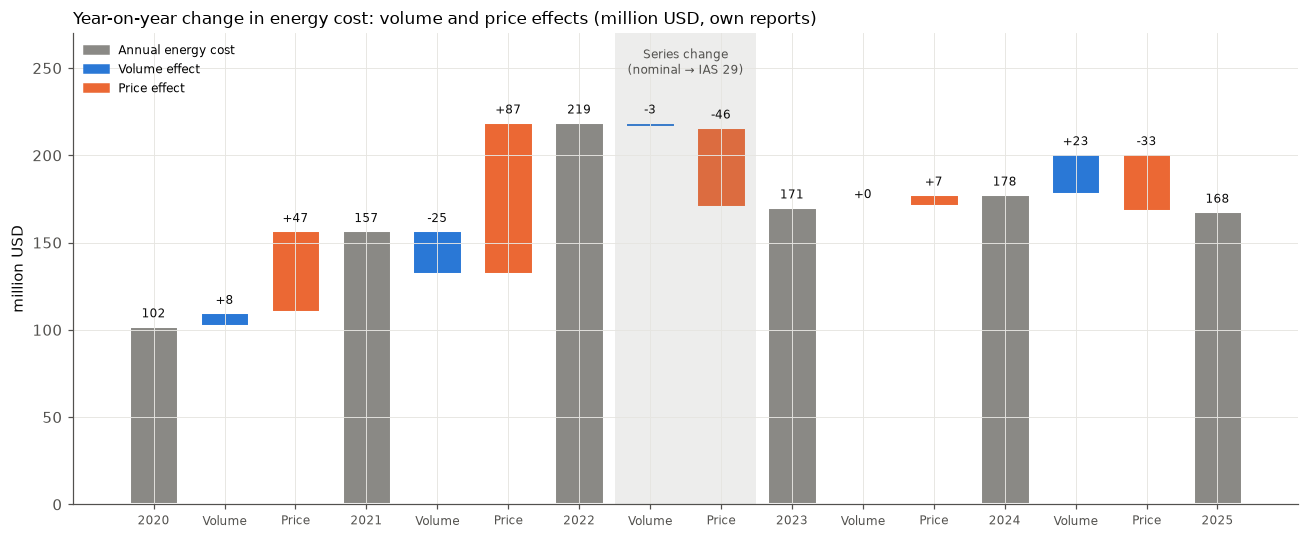

In [9]:
# Waterfall chart: 2020 cost → volume and price effect of each transition → interim year totals → 2025
steps = [("2020", d.loc[2020, "energy_cost_usd"] / 1e6, "total", None)]
for y in range(2021, 2026):
    t = f"{y-1}→{y}"
    steps.append(("Volume", pv.loc[t, "volume_effect_mn_usd"], "vol", t))
    steps.append(("Price", pv.loc[t, "price_effect_mn_usd"], "price", t))
    steps.append((str(y), d.loc[y, "energy_cost_usd"] / 1e6, "total", None))

fig, ax = plt.subplots(figsize=(12, 5))
level = 0.0
for i, (lab, val, kind, t) in enumerate(steps):
    if kind == "total":
        ax.bar(i, val, color=C_GREY, width=0.7, edgecolor="white", linewidth=2)
        ax.text(i, val + 3, f"{val:.0f}", ha="center", va="bottom", fontsize=8, color=C_INK)
        level = val
    else:
        color = C_BLUE if kind == "vol" else C_ORANGE
        bottom = level if val >= 0 else level + val
        ax.bar(i, abs(val), bottom=bottom, color=color, width=0.7, edgecolor="white", linewidth=2)
        ax.text(i, level + max(val, 0) + 3, f"{val:+.0f}", ha="center", va="bottom", fontsize=8, color=C_INK)
        level += val
# Shade the transition that spans the series change
i0 = [i for i, s in enumerate(steps) if s[3] == "2022→2023"]
ax.axvspan(min(i0) - 0.5, max(i0) + 0.5, color=C_GREY, alpha=0.15, linewidth=0)
ax.text(np.mean(i0), 262, "Series change\n(nominal → IAS 29)", ha="center", va="top", fontsize=8, color=C_MUTED)
ax.set_xticks(range(len(steps)))
ax.set_xticklabels([s[0] for s in steps], fontsize=8)
ax.set_ylabel("million USD")
ax.set_ylim(0, 270)
ax.set_title("Year-on-year change in energy cost: volume and price effects (million USD, own reports)", loc="left", fontsize=11)
ax.legend(handles=[Patch(color=C_GREY, label="Annual energy cost"), Patch(color=C_BLUE, label="Volume effect"),
                   Patch(color=C_ORANGE, label="Price effect")], loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "01_price_volume_waterfall.png", bbox_inches="tight")
plt.show()

**Sensitivity check – two years from the same report.** When the difference between two reports is taken in the IAS 29 period, both values must be in the same purchasing power. The main table above uses the `own` rows (different reports). Below we recompute the same transitions with the prior year taken **from the comparative column of the current report** (e.g. for 2023→2024 the 2023 value comes from the 2024 report). In these rows the energy cost, MWh and purchasing power all belong to the same report; however, the prior year's scope and classification may also have changed in the current report (2022: SBS included; 2024: Mannok's 12 months in the physical data, ~TRY 1.1 billion of energy cost moved to "other production").

In [10]:
rows = []
for y in [2023, 2024, 2025]:
    a = master[(master["year"] == y - 1) & (master["view"] == f"restated_in_{y}")].iloc[0]
    b = own.loc[y]
    P0, P1, vol, price = price_volume(a["energy_cost_usd"], a["total_energy_consumption"],
                                      b["energy_cost_usd"], b["total_energy_consumption"])
    rows.append({"transition": f"{y-1}→{y}", "prev_year_from": f"{y} report",
                 "cost_prev_mn_usd": a["energy_cost_usd"] / 1e6, "cost_curr_mn_usd": b["energy_cost_usd"] / 1e6,
                 "delta_mn_usd": (b["energy_cost_usd"] - a["energy_cost_usd"]) / 1e6,
                 "volume_effect_mn_usd": vol / 1e6, "price_effect_mn_usd": price / 1e6,
                 "price_prev_usd_mwh": P0, "price_curr_usd_mwh": P1})
pv_same = pd.DataFrame(rows).set_index("transition")

compare = pd.DataFrame({
    "delta_own": pv.loc[pv_same.index, "delta_mn_usd"], "delta_same_report": pv_same["delta_mn_usd"],
    "price_effect_own": pv.loc[pv_same.index, "price_effect_mn_usd"], "price_effect_same_report": pv_same["price_effect_mn_usd"],
    "volume_effect_own": pv.loc[pv_same.index, "volume_effect_mn_usd"], "volume_effect_same_report": pv_same["volume_effect_mn_usd"],
})
display(pv_same.round(1))
compare.round(1)

,prev_year_from,cost_prev_mn_usd,cost_curr_mn_usd,delta_mn_usd,volume_effect_mn_usd,price_effect_mn_usd,price_prev_usd_mwh,price_curr_usd_mwh
transition,,,,,,,,
2022→2023,2023 report,267.8,170.6,-97.1,-10.4,-86.7,40.5,26.9
2023→2024,2024 report,205.6,178.0,-27.6,0.2,-27.8,32.4,28.0
2024→2025,2025 report,165.6,168.2,2.6,14.5,-12.0,25.1,23.4


,delta_own,delta_same_report,price_effect_own,price_effect_same_report,volume_effect_own,volume_effect_same_report
transition,,,,,,
2022→2023,-48.7,-97.1,-45.8,-86.7,-2.9,-10.4
2023→2024,7.4,-27.6,7.2,-27.8,0.2,0.2
2024→2025,-9.8,2.6,-33.0,-12.0,23.2,14.5


**What we see:** Between 2020 and 2022 most of the increase in energy cost comes together with the price effect (price effect 2021: +47, 2022: +87 million USD); the volume effect is negative in 2022 (−25, the year the Central Anatolia plants were sold). The decline between 2022 and 2025 is also mainly on the price side: with own reports the price effects total −72 million USD and the volume effects +21 million USD (the volume increase in 2025 coincides with Mannok's full-year consolidation).

*Note:* The choice of method changes the result. The 2023→2024 transition is +7 million USD with own reports (price effect +7) but −28 million USD within the 2024 report (price effect −28). The difference comes from converting IAS 29 amounts to dollars at the year-end rate: in 2024 TRY inflation was higher than the rise in the exchange rate, so the same 2023 cost carries a ~20% higher dollar value in the 2024 report. The direction (weight of the price effect) is the same under both methods in 2022→2023 and 2024→2025 and differs in 2023→2024.

## 5. Energy intensity (per ton of clinker)

Two indicators:
- **Energy cost per ton of clinker (USD/ton)** = energy cost (USD) / clinker production. Available from 2016; it reflects both price and physical efficiency.
- **Energy consumption per ton of clinker (MWh/ton)** = total energy consumption / clinker production. 2020–2025 only. Because the numerator also includes the energy of activities other than clinker (grinding, ready-mix concrete, building materials), this is a group-wide intensity indicator, not a "clinker energy intensity". For comparison, the ratio based on the clinker production energy stated in the reports (`clinker_energy_consumption`) is also shown.

In [11]:
inten = pd.DataFrame({
    "energy_cost_usd_per_t_clinker": own["energy_cost_usd"] / own["clinker_production"],
    "mwh_per_t_clinker": own["total_energy_consumption"] / own["clinker_production"],
    "clinker_mwh_per_t_clinker": own["clinker_energy_consumption"] / own["clinker_production"],
    "specific_heat_mj_per_t": own["specific_heat_consumption"],
    "clinker_production_mn_t": own["clinker_production"] / 1e6,
    "basis": own["basis"],
})
r2022_usd_t = r2022["energy_cost_usd"] / r2022["clinker_production"]
r2022_mwh_t = r2022["total_energy_consumption"] / r2022["clinker_production"]
inten.round(3)

,energy_cost_usd_per_t_clinker,mwh_per_t_clinker,clinker_mwh_per_t_clinker,specific_heat_mj_per_t,clinker_production_mn_t,basis
year,,,,,,
2016,16.028,NaN,NaN,NaN,5.539,nominal
2017,15.638,NaN,NaN,NaN,6.102,nominal
2018,16.768,NaN,NaN,NaN,5.791,nominal
2019,16.515,NaN,NaN,NaN,5.200,nominal
2020,16.013,1.115,1.059,3563.0,6.400,nominal
2021,22.701,1.108,1.091,3620.0,6.920,nominal
2022,37.420,1.099,1.056,3782.0,5.860,nominal
2023,34.328,1.278,1.219,3627.0,4.970,tms29
2024,32.567,1.164,1.063,NaN,5.465,tms29


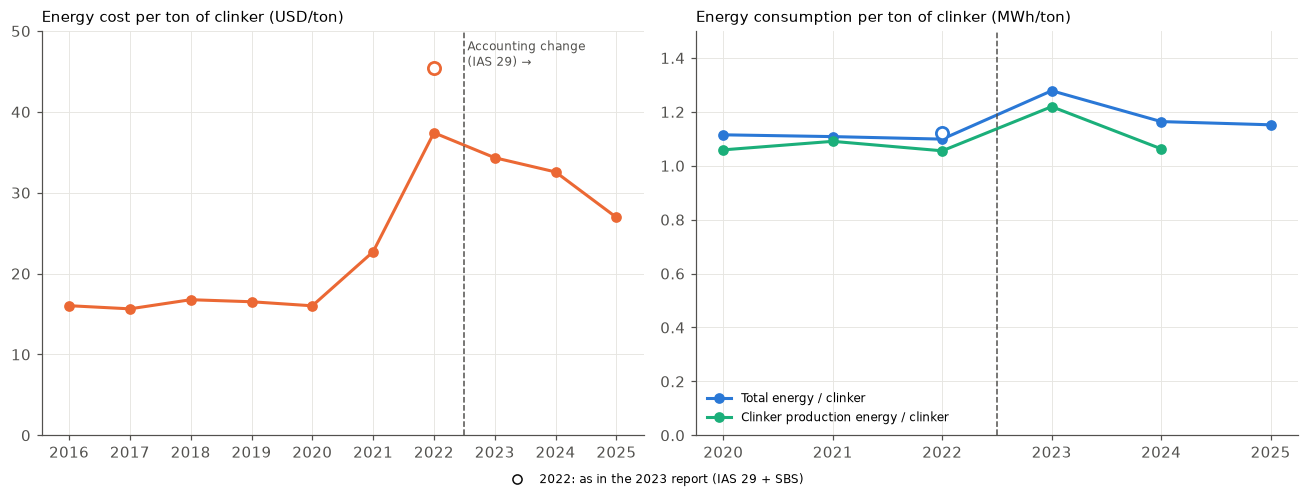

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
s = inten["energy_cost_usd_per_t_clinker"].dropna()
ax.plot(s.index, s, marker="o", color=C_ORANGE)
ax.plot(2022, r2022_usd_t, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_ORANGE,
        markeredgewidth=1.8, linestyle="none")
ax.set_title("Energy cost per ton of clinker (USD/ton)", loc="left", fontsize=10)
ax.set_xticks(range(2016, 2026)); ax.set_ylim(0, 50)
mark_series_break(ax)

ax = axes[1]
s1 = inten["mwh_per_t_clinker"].dropna(); s2 = inten["clinker_mwh_per_t_clinker"].dropna()
ax.plot(s1.index, s1, marker="o", color=C_BLUE, label="Total energy / clinker")
ax.plot(s2.index, s2, marker="o", color=C_AQUA, label="Clinker production energy / clinker")
ax.plot(2022, r2022_mwh_t, marker="o", markersize=8, markerfacecolor="white", markeredgecolor=C_BLUE,
        markeredgewidth=1.8, linestyle="none")
ax.set_title("Energy consumption per ton of clinker (MWh/ton)", loc="left", fontsize=10)
ax.set_xticks(range(2020, 2026)); ax.set_ylim(0, 1.5)
mark_series_break(ax, label=False)
ax.legend(loc="lower left", fontsize=8)

fig.legend(handles=[Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor=C_INK, linestyle="none",
                           label="2022: as in the 2023 report (IAS 29 + SBS)")],
           loc="lower center", fontsize=8, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()
fig.savefig(FIGS / "01_energy_intensity_per_ton_clinker.png", bbox_inches="tight")
plt.show()

**What we see:** Energy cost per ton of clinker is in the 16–17 USD/ton band in 2016–2020, rises to 37 USD/ton in 2022 and falls to 27 USD/ton in 2025; still ~66% above the pre-crisis level (2016–2020 average ~16.2). Physical intensity (MWh/ton) is in the 1.10–1.28 range in 2020–2025 and shows no clear downward trend; most of the change in cost per ton is on the price side.

*Note:* The jump to 1.28 MWh/ton in 2023 comes together with taking 2023 clinker production from the report's total line (4.97 million tons); the sum of the same report's components is 5.35 million tons. With 5.35 the ratio would be ~1.19. Because the 2025 production table excludes Mannok, the 2025 ratios may also be biased upwards.

## 6. Comparison with a market reference price (H2 test)

To see how much of the change in the implied price moves together with market prices, we build a **market reference index**:

- **Coal:** World Bank "Coal, Australian" and "Coal, South African" (USD/ton), annual average. The main index uses the average of the two series; each is also shown separately (sensitivity).
- **Electricity:** EPİAŞ day-ahead market price (PTF) (hourly, TRY/MWh) → monthly average → USD/MWh at the same month's EVDS average rate → annual average.
- **Weight:** electricity share = electricity consumption / total energy consumption (own reports; ~9–11% in 2020–2025). The thermal part is represented by coal.
- **Market index (2020 = 100)** = electricity share × PTF index + (1 − electricity share) × coal index. **Çimsa index** = implied price (USD/MWh), 2020 = 100. **Gap** = Çimsa − market.

The data were produced with `src/08_reference_prices.py` (`output/tables/reference_prices_annual.csv`); the checks are in `output/checks/reference_prices_checks.csv`.

**Limitations:**
- **The implied price is not a market price.** It is the weighted average cost of all sources; it also includes self-generated solar and waste heat electricity, alternative fuels, and inventory and contract timing.
- **Coal is only an approximate indicator for petcoke.** Çimsa's main fuel is petcoke; coal was used because there is no free petcoke series. The two fuel prices move in the same direction but not necessarily by the same amount.
- **The PTF is not Çimsa's actual electricity purchase price.** The company buys part of its electricity through bilateral contracts (e.g. Enerjisa) and generates part of it itself.
- **Dollar conversion of IAS 29 years:** The 2023–2025 implied price may be slightly high because it is converted at the year-end rate (estimated 2023 ~1%, 2024 ~6%, 2025 ~2%). The market index, by contrast, was converted at the monthly average rate.
- **Base year 2020:** A year in which coal prices were low because of the pandemic. Index ratios are sensitive to the choice of base year.

In [13]:
import importlib.util

# Weights are computed with the function in src/08 (same source as the check file)
_spec = importlib.util.spec_from_file_location("reference_prices", ROOT / "src" / "08_reference_prices.py")
reference_prices = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(reference_prices)

ref = pd.read_csv(TABLES / "reference_prices_annual.csv").set_index("year")
ref["coal_avg_usd_t"] = ref[["coal_australia_usd_t", "coal_south_africa_usd_t"]].mean(axis=1)
weights = reference_prices.electricity_weights(master).set_index("year")
ref[["coal_australia_usd_t", "coal_south_africa_usd_t", "coal_avg_usd_t", "ptf_try_mwh", "ptf_usd_mwh"]].round(1)

,coal_australia_usd_t,coal_south_africa_usd_t,coal_avg_usd_t,ptf_try_mwh,ptf_usd_mwh
year,,,,,
2016,66.1,64.0,65.0,140.3,46.2
2017,88.5,85.1,86.8,163.9,45.0
2018,107.0,97.6,102.3,231.4,47.4
2019,77.9,71.9,74.9,260.2,46.0
2020,60.8,65.7,63.2,278.7,40.1
2021,138.0,119.8,129.0,506.4,55.3
2022,344.9,240.6,292.7,2505.6,147.3
2023,172.8,119.1,145.9,2190.8,96.7
2024,136.2,105.8,121.0,2233.4,68.0


In [14]:
weights[["electricity_weight", "weight_year", "weight_source"]].assign(electricity_weight=lambda x: x["electricity_weight"].round(4))

,electricity_weight,weight_year,weight_source
year,,,
2016,0.0962,2020,no data; nearest year (2020) used; annual_mast...
2017,0.0962,2020,no data; nearest year (2020) used; annual_mast...
2018,0.0962,2020,no data; nearest year (2020) used; annual_mast...
2019,0.0962,2020,no data; nearest year (2020) used; annual_mast...
2020,0.0962,2020,same year; annual_master own 2020: electricity...
2021,0.0918,2021,same year; annual_master own 2021: own report
2022,0.0923,2022,same year; annual_master own 2022: own report
2023,0.1006,2023,same year; annual_master own 2023: own report
2024,0.1009,2024,same year; annual_master own 2024: own report


**Context: Coal and electricity prices (USD, 2016–2025).** Coal (USD/ton) and the PTF (USD/MWh) are in different units, so they are shown in two separate panels.

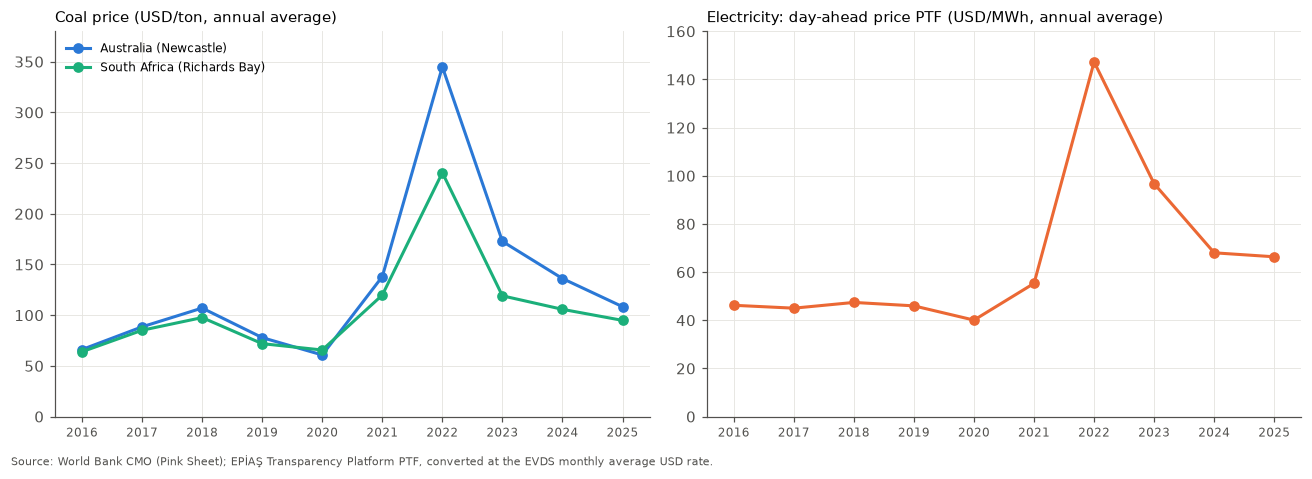

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
yrs_all = ref.index.values

ax = axes[0]
ax.plot(yrs_all, ref["coal_australia_usd_t"], marker="o", color=C_BLUE, label="Australia (Newcastle)")
ax.plot(yrs_all, ref["coal_south_africa_usd_t"], marker="o", color=C_AQUA, label="South Africa (Richards Bay)")
ax.set_title("Coal price (USD/ton, annual average)", loc="left", fontsize=10)
ax.set_ylim(0, 380)
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
ax.plot(yrs_all, ref["ptf_usd_mwh"], marker="o", color=C_ORANGE)
ax.set_title("Electricity: day-ahead price PTF (USD/MWh, annual average)", loc="left", fontsize=10)
ax.set_ylim(0, 160)

for ax in axes:
    ax.set_xticks(yrs_all)
    ax.tick_params(axis="x", labelsize=8)
fig.text(0.01, -0.02, "Source: World Bank CMO (Pink Sheet); EPİAŞ Transparency Platform PTF, converted at the EVDS monthly average USD rate.",
         fontsize=7.5, color=C_MUTED)
fig.tight_layout()
fig.savefig(FIGS / "01_reference_prices_coal_ptf.png", bbox_inches="tight")
plt.show()

**What we see:** Coal prices are at their lowest in 2020 (average 63 USD/ton), rise roughly 4.6-fold by 2022 (293 USD/ton) and fall back to 102 USD/ton in 2025. The PTF follows a similar path: 40 → 147 → 66 USD/MWh. In 2025 both indicators are above their 2016–2019 average: coal by ~24%, the PTF by ~44%.

In [16]:
def to_index(s, base=2020):
    return s / s.loc[base] * 100

yrs_cmp = range(2020, 2026)
w = weights["electricity_weight"]
ptf_ix = to_index(ref["ptf_usd_mwh"])
idx = pd.DataFrame({"electricity_weight": w})
for name, col in [("avg", "coal_avg_usd_t"), ("australia", "coal_australia_usd_t"), ("south_africa", "coal_south_africa_usd_t")]:
    idx[f"market_index_{name}"] = w * ptf_ix + (1 - w) * to_index(ref[col])
idx["cimsa_index"] = to_index(own.loc[2020:2025, "implied_energy_price_usd_per_mwh"])
for name in ["avg", "australia", "south_africa"]:
    idx[f"gap_{name}"] = idx["cimsa_index"] - idx[f"market_index_{name}"]
idx = idx.loc[yrs_cmp]
idx.round(1)

,electricity_weight,market_index_avg,market_index_australia,market_index_south_africa,cimsa_index,gap_avg,gap_australia,gap_south_africa
year,,,,,,,,
2020,0.1,100.0,100.0,100.0,100.0,0.0,0.0,0.0
2021,0.1,197.9,218.9,178.5,142.6,-55.3,-76.3,-35.8
2022,0.1,454.2,549.0,366.5,237.1,-217.1,-311.9,-129.4
2023,0.1,231.9,279.9,187.4,186.9,-45.0,-93.0,-0.5
2024,0.1,189.2,218.5,162.0,194.8,5.6,-23.7,32.8
2025,0.1,161.3,176.9,146.9,162.9,1.5,-14.1,16.0


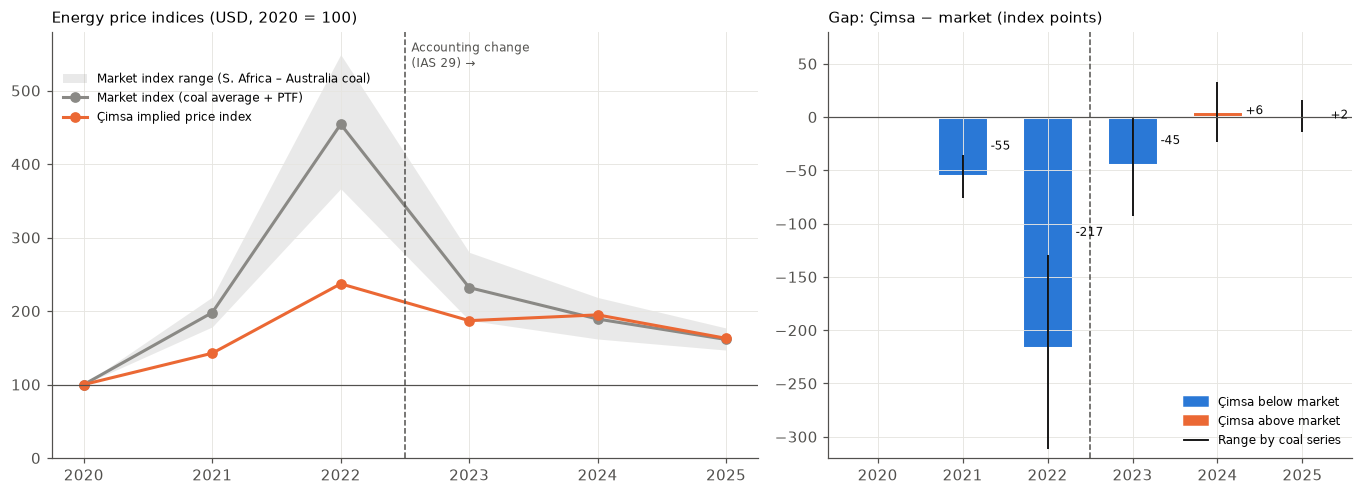

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})
x = np.array(list(yrs_cmp))

# (a) indices
ax = axes[0]
ax.fill_between(x, idx["market_index_south_africa"], idx["market_index_australia"], color=C_GREY, alpha=0.18, linewidth=0,
                label="Market index range (S. Africa – Australia coal)")
ax.plot(x, idx["market_index_avg"], marker="o", color=C_GREY, label="Market index (coal average + PTF)")
ax.plot(x, idx["cimsa_index"], marker="o", color=C_ORANGE, label="Çimsa implied price index")
ax.axhline(100, color=C_MUTED, linewidth=0.8)
mark_series_break(ax)
ax.set_xticks(x)
ax.set_ylim(0, 580)
ax.set_title("Energy price indices (USD, 2020 = 100)", loc="left", fontsize=10)
ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, 0.93))

# (b) gap: main value as bar, sensitivity range as line
ax = axes[1]
gap = idx["gap_avg"]
ax.bar(x, gap, width=0.6, color=[C_BLUE if g < 0 else C_ORANGE for g in gap], edgecolor="white", linewidth=2)
lo = idx[["gap_australia", "gap_south_africa"]].min(axis=1)
hi = idx[["gap_australia", "gap_south_africa"]].max(axis=1)
ax.vlines(x, lo, hi, color=C_INK, linewidth=1.2)
for xi, g in zip(x[1:], gap.iloc[1:]):  # base year 2020 (gap 0) is not labelled
    ax.text(xi + 0.33, g / 2 if abs(g) > 20 else g, f"{g:+.0f}", ha="left", va="center", fontsize=8, color=C_INK)
ax.axhline(0, color=C_MUTED, linewidth=0.8)
mark_series_break(ax, label=False)
ax.set_xticks(x)
ax.set_ylim(-320, 80)
ax.set_title("Gap: Çimsa − market (index points)", loc="left", fontsize=10)
ax.legend(handles=[Patch(color=C_BLUE, label="Çimsa below market"), Patch(color=C_ORANGE, label="Çimsa above market"),
                   Line2D([], [], color=C_INK, linewidth=1.2, label="Range by coal series")],
          loc="lower right", fontsize=8)

fig.tight_layout()
fig.savefig(FIGS / "01_cimsa_vs_market_energy_index.png", bbox_inches="tight")
plt.show()

**What we see:**
- **2021–2023:** Çimsa's implied price rises much less than the market index. In 2022 the market index is 454 and the Çimsa index 237 (gap −217 points; −129 to −312 depending on the coal series). The gap narrows to −45 in 2023.
- **2024–2025:** The Çimsa index is at almost the same level as the market index (2024: 195 / 189, 2025: 163 / 161; gap +6 and +2). However, depending on the coal series used, the gap ranges from −24 to +33 in 2024 and from −14 to +16 in 2025; so even its sign is uncertain. Net of the effect of converting IAS 29 amounts at the year-end rate, the 2024 Çimsa index would be ~183 and the gap would approach zero.
- **Reading:** In the crisis years Çimsa passes only part of the rise in market prices through to its implied price; in the decline after 2022 it also falls less than the market. By 2025, cumulatively versus 2020, it is at the same place as the market. How much the gap in the crisis years is related to inventory and contract timing, the price gap between petcoke and coal, alternative fuels or self-generated electricity cannot be separated with this data.

### 6.1 Base-year sensitivity (2020 = 100 and 2021 = 100)

2020 was a year of very low coal prices because of the pandemic. When the indices are built on this low base, the rise in the market index looks large. To see how sensitive the result is to the base year, we repeat the same calculation with **2021 = 100**. Weights and prices are the same; only the base year changes. The coal-country sensitivity (Australia / South Africa) is shown for both bases.

In [18]:
def build_index(base):
    ix = lambda s: s / s.loc[base] * 100
    out = pd.DataFrame(index=list(yrs_cmp))
    for name, col in [("avg", "coal_avg_usd_t"), ("australia", "coal_australia_usd_t"), ("south_africa", "coal_south_africa_usd_t")]:
        out[f"market_{name}"] = (w * ix(ref["ptf_usd_mwh"]) + (1 - w) * ix(ref[col])).loc[out.index]
    out["cimsa"] = ix(own.loc[2020:2025, "implied_energy_price_usd_per_mwh"])
    for name in ["avg", "australia", "south_africa"]:
        out[f"gap_{name}"] = out["cimsa"] - out[f"market_{name}"]
    return out

BASES = [2020, 2021]
idx_by_base = {b: build_index(b) for b in BASES}
base_cmp = pd.concat({f"base {b}": idx_by_base[b] for b in BASES}, axis=1)
base_cmp.round(1)

base 2020                                                                                     base 2021                                                                                   
     market_avg market_australia market_south_africa  cimsa gap_avg gap_australia gap_south_africa market_avg market_australia market_south_africa  cimsa gap_avg gap_australia gap_south_africa
2020      100.0            100.0               100.0  100.0     0.0           0.0              0.0       51.3             46.8                56.5   70.1    18.8          23.4             13.6
2021      197.9            218.9               178.5  142.6   -55.3         -76.3            -35.8      100.0            100.0               100.0  100.0     0.0           0.0              0.0
2022      454.2            549.0               366.5  237.1  -217.1        -311.9           -129.4      230.6            251.4               206.8  166.2   -64.4         -85.1            -40.5
2023      231.9            279.9               187.4  186.9   -45.0         -93.0             -0.5      119.4            130.2               107.0  131.1    11.7           0.9             24.1
2024      189.2            218.5               162.0  194.8     5.6         -23.7             32.8       96.7            101.1                91.8  136.6    39.8          35.5             44.8
2025      161.3            176.9               146.9  162.9     1.5         -14.1             16.0       83.4             83.1                83.7  114.2    30.8          31.1             30.5

In [19]:
# Summary: gap under both bases (main value and range by coal series)
gap_summary = pd.concat({
    f"base {b}": pd.DataFrame({
        "gap_avg": idx_by_base[b]["gap_avg"],
        "gap_min": idx_by_base[b][["gap_australia", "gap_south_africa"]].min(axis=1),
        "gap_max": idx_by_base[b][["gap_australia", "gap_south_africa"]].max(axis=1),
    }) for b in BASES}, axis=1)
gap_summary.round(1)

base 2020                 base 2021                
       gap_avg gap_min gap_max   gap_avg gap_min gap_max
2020       0.0     0.0     0.0      18.8    13.6    23.4
2021     -55.3   -76.3   -35.8       0.0     0.0     0.0
2022    -217.1  -311.9  -129.4     -64.4   -85.1   -40.5
2023     -45.0   -93.0    -0.5      11.7     0.9    24.1
2024       5.6   -23.7    32.8      39.8    35.5    44.8
2025       1.5   -14.1    16.0      30.8    30.5    31.1

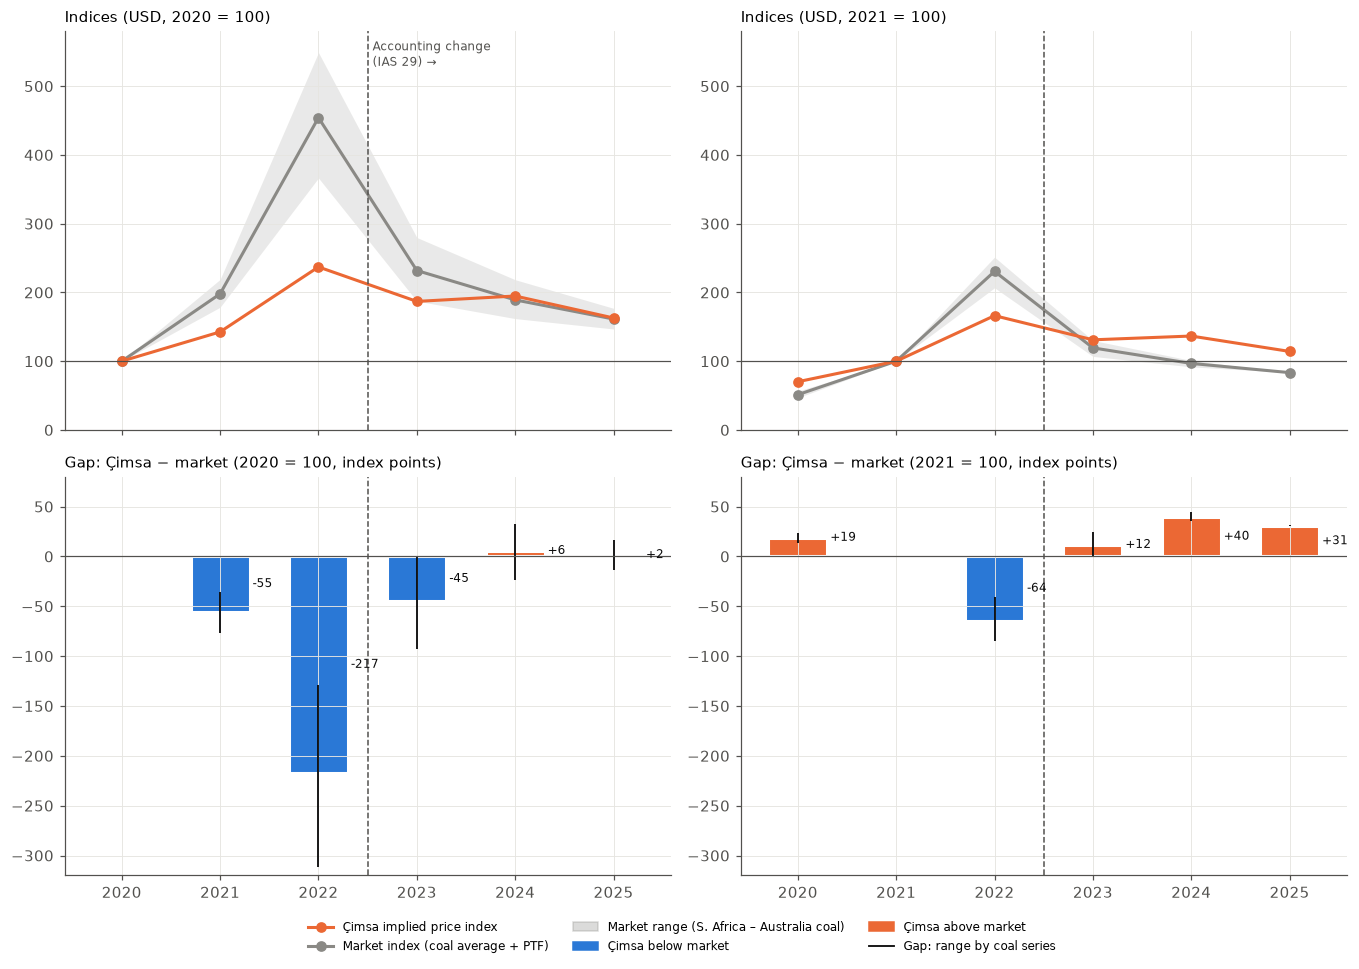

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.4), sharex=True)
x = np.array(list(yrs_cmp))

for col, b in enumerate(BASES):
    d_ = idx_by_base[b]
    # top: indices
    ax = axes[0, col]
    ax.fill_between(x, d_["market_south_africa"], d_["market_australia"], color=C_GREY, alpha=0.18, linewidth=0)
    ax.plot(x, d_["market_avg"], marker="o", color=C_GREY)
    ax.plot(x, d_["cimsa"], marker="o", color=C_ORANGE)
    ax.axhline(100, color=C_MUTED, linewidth=0.8)
    mark_series_break(ax, label=(col == 0))
    ax.set_ylim(0, 580)
    ax.set_title(f"Indices (USD, {b} = 100)", loc="left", fontsize=10)
    # bottom: gap
    ax = axes[1, col]
    gap = d_["gap_avg"]
    lo = d_[["gap_australia", "gap_south_africa"]].min(axis=1)
    hi = d_[["gap_australia", "gap_south_africa"]].max(axis=1)
    ax.bar(x, gap, width=0.6, color=[C_BLUE if g < 0 else C_ORANGE for g in gap], edgecolor="white", linewidth=2)
    ax.vlines(x, lo, hi, color=C_INK, linewidth=1.2)
    for xi, g in zip(x, gap):
        if xi == b:
            continue  # the gap is 0 by definition in the base year
        ax.text(xi + 0.33, g / 2 if abs(g) > 20 else g, f"{g:+.0f}", ha="left", va="center", fontsize=8, color=C_INK)
    ax.axhline(0, color=C_MUTED, linewidth=0.8)
    mark_series_break(ax, label=False)
    ax.set_ylim(-320, 80)
    ax.set_xticks(x)
    ax.set_title(f"Gap: Çimsa − market ({b} = 100, index points)", loc="left", fontsize=10)

legend_items = [Line2D([], [], color=C_ORANGE, marker="o", label="Çimsa implied price index"),
                Line2D([], [], color=C_GREY, marker="o", label="Market index (coal average + PTF)"),
                Patch(color=C_GREY, alpha=0.3, label="Market range (S. Africa – Australia coal)"),
                Patch(color=C_BLUE, label="Çimsa below market"), Patch(color=C_ORANGE, label="Çimsa above market"),
                Line2D([], [], color=C_INK, linewidth=1.2, label="Gap: range by coal series")]
fig.legend(handles=legend_items, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout()
fig.savefig(FIGS / "01_base_year_sensitivity.png", bbox_inches="tight")
plt.show()

**What we see (both base years together):**
- **2022:** Under both bases Çimsa's implied price rises much less than the market. The gap is −217 points on the 2020 base and −64 points on the 2021 base; the range by coal series is −312 / −129 and −85 / −41 respectively. This result holds regardless of the base year and the coal series.
- **2023–2025:** The result depends on the base year. On the 2020 base Çimsa appears to be level with the market (2025: +2 points; range −14 / +16). On the 2021 base, however, Çimsa has **fallen less** than the market and stays above it: +12 in 2023, +40 in 2024 and +31 points in 2025. In 2024–2025 this gap is positive under all three coal variants (+31 to +45). In 2025 the market index is 83 (below 2021) and the Çimsa index 114.
- **Pattern:** Çimsa's implied price tracks the market **with a lag and in a smoothed way**. It rises less when the market rises and falls later and less when the market falls. Ending 2025 level with the market on the 2020 base is also consistent with this pattern: an advantage on the way up, a disadvantage on the way down.
- **What cannot be separated:** This pattern may be consistent with long-term supply contracts, inventory (fuel in stock reaching the income statement with a delay), the gap between petcoke and coal prices, and the use of alternative fuels. These effects cannot be separated from each other with the publicly available data.
- **Note on 2024:** Part of the 2024 gap may come from converting IAS 29 amounts to dollars at the year-end rate (~6% for 2024). If this adjustment is applied, on the 2021 base the 2024 Çimsa index would be ~129 instead of ~137, and the gap ~+32 instead of +40 points. The gap narrows but does not disappear.

**Decision:** The main result is the pattern that holds under both base years (lagged/smoothed tracking). In the presentation the main chart will use 2021 = 100 (2020 is unusual because of the pandemic), with 2020 = 100 shown as a supplement.

## 7. Interim findings and preliminary assessment of H2

**Section summaries**
1. **Energy weight:** The share of energy in production cost fell from its 60% peak in 2022 to 21% in 2025; this is clearly below the 33–36% reference band in H2. Gross margin stayed in the 17–21% band over the same period.
2. **Physical consumption and price:** Physical consumption is flat in 2020–2025 (6.4–7.7 million MWh); the implied price fell from its 2022 peak (34 USD/MWh) to 23 USD/MWh in 2025 but remains above the 2020 level (14).
3. **Price-volume:** The decline in energy cost after 2022 comes mainly together with the price effect; the volume effect is small and positive in 2025. In the 2023→2024 transition the choice of method (own report / same report) changes the direction of the effect.
4. **Intensity:** There is no clear improvement in physical energy consumption per ton of clinker between 2020 and 2025; cost per ton moves with the price.
5. **Market comparison:** Çimsa's implied price rose much less than the market in 2022; this result holds regardless of the base year and the coal series. After 2023, however, it fell less than the market: on the 2021 base it is +31 to +45 points above the market in 2024–2025, and on the 2020 base level with the market. The pattern is consistent with lagged and smoothed tracking of the market.

**Preliminary assessment of H2: PARTIALLY (updated)**
- *Supporting:* The fall in energy cost and in the implied price after 2022 occurs together with the fall in market prices. In the price-volume decomposition the decline is also mainly on the price side.
- *Not supported:* **There is no lasting, company-specific advantage on the price side.** The implied price, which stayed clearly below the market in the crisis year (2022), does not fall below the market after 2023: on the 2020 base it is level with the market, on the 2021 base above it. The part of H2 that links "the part below the band" to the green transformation does not appear to leave a trace in the price. There is no clear decline in physical intensity (MWh/ton clinker) either. The alternative fuel rate in grey cement dropped to 10% in 2024 and returned to 28% in 2025.
- *Open:* In 2025 the implied price is 1.6 times that of 2020, while the energy share (21%) is below the pre-crisis band (33–36%). This seems to be related less to the energy price than to the other cost items and the portfolio structure. Possible elements: consolidation of less energy-intensive businesses such as SBS and Mannok, the path of other cost items under IAS 29, and the energy → "other production" reclassification in the 2025 report. This explanation will be tested in the **mix effect notebook (02)**.
- *Cannot be separated:* How much the smoothing pattern is related to long-term contracts, inventory, the petcoke–coal price gap or alternative fuels cannot be separated with this data.

**Note for H4 (resilience):** The implied price tracking the market in a smoothed way looks like a buffer that delays part of the cost increase in sudden shocks such as 2022. However, the same pattern gives this advantage back when prices fall (2024–2025 on the 2021 base). So the burden of the shock does not disappear; it is spread over time. When H4 is assessed, this pattern (lower cost in the shock year, higher afterwards) should be considered together with margin volatility.

**Next step:** The contribution of portfolio change (the mix effect) to the energy share will be covered in the next notebook (02) with segment data.